# Agentes Basados en Conocimiento

**Modelos Basados en Agentes · Representación del conocimiento y razonamiento lógico**

Esta clase sigue la presentación del capítulo 7 (*Logical Agents*) del libro de **Stuart Russell y Peter Norvig, *Artificial Intelligence: A Modern Approach***: primero la arquitectura de un agente basado en conocimiento, luego la lógica que le permite razonar y, finalmente, dos ejercicios en Mesa: una versión simplificada del **Mundo del Wumpus** y una versión simplificada del **Buscaminas**.

## 1. De los reflejos al razonamiento

En los notebooks anteriores vimos dos tipos de agentes:

* `ExplorerAgent`: guarda una **memoria** (lista de posiciones con comida) y aplica una regla fija.
* `LearningAgent`: acumula **valores** (`q_values`) a partir de recompensas y mejora por prueba y error.

En ambos casos el "conocimiento" está *implícito*: escondido en el código de las reglas o en números. Eso tiene un límite: el agente no puede responder preguntas como *"¿es seguro entrar a la celda (2, 3), que nunca he visitado?"* ni **combinar** dos hechos para obtener un tercero.

Un **agente basado en conocimiento** guarda afirmaciones **explícitas** sobre el mundo y deriva nuevas afirmaciones por **inferencia lógica**. Russell y Norvig (Artificial Intelligence: A Modern Approach) destacan tres ventajas de este diseño: se le pueden dar *nuevas metas* de forma explícita, puede *adquirir competencia rápidamente* si se le comunica nuevo conocimiento, y se *adapta a los cambios* actualizando lo que sabe, sin reescribir el programa.

| | Agente reactivo | Agente con aprendizaje | Agente basado en conocimiento |
|---|---|---|---|
| **¿Qué almacena?** | Casi nada (o una memoria simple) | Valores numéricos (`q_values`) | Oraciones lógicas (la KB) |
| **¿Cómo decide?** | Reglas *si–entonces* fijas | Maximiza lo aprendido (ε‑greedy) | Infiere consecuencias de la KB |
| **¿Cómo incorpora <br> información?** | No la incorpora | Por experiencia y recompensas | `TELL` de percepciones + deducción |
| **¿Qué necesita?** | Reglas escritas a mano | Muchas interacciones | Reglas del mundo correctas <br> (conocimiento de fondo) |
| **Garantía** | Ninguna | Mejora estadística con la experiencia | Si la KB es verdadera y la inferencia es sólida,<br> las conclusiones son verdaderas |

## 2. Anatomía de un agente basado en conocimiento

El componente central es la **base de conocimiento** (*knowledge base*, KB): un conjunto de **oraciones** escritas en un **lenguaje de representación del conocimiento**. Cada oración es una afirmación sobre el mundo. Lo que la KB contiene al inicio se llama **conocimiento de fondo** (*background knowledge*), por ejemplo, las reglas del mundo.

Sólo hay dos operaciones para interactuar con ella:

* `TELL(KB, oración)`: **añade** una oración a la KB.
* `ASK(KB, consulta)`: **pregunta** si la consulta se sigue de lo que la KB contiene. Responder puede requerir **inferencia**: derivar oraciones nuevas a partir de las que ya están.

En cada instante $t$ el agente ejecuta el siguiente ciclo (algoritmo `KB-AGENT` del libro):

```bash
function KB-AGENT(percepto) devuelve una acción
    persistente: KB, una base de conocimiento
                 t, un contador de tiempo, inicialmente 0

    TELL(KB, MAKE-PERCEPT-SENTENCE(percepto, t))    # 1. "esto fue lo que percibí"
    acción ← ASK(KB, MAKE-ACTION-QUERY(t))          # 2. "¿qué debo hacer?"
    TELL(KB, MAKE-ACTION-SENTENCE(acción, t))       # 3. "esto fue lo que hice"
    t ← t + 1
    devolver acción
```

Los detalles del lenguaje de representación quedan ocultos en tres funciones: `MAKE-PERCEPT-SENTENCE` convierte una percepción en una oración, `MAKE-ACTION-QUERY` construye la pregunta "¿qué acción conviene en el instante $t$?" y `MAKE-ACTION-SENTENCE` registra la acción ejecutada.

### Dos formas de describir un agente

* **Nivel del conocimiento** (Newell, 1982): sólo se dice *qué sabe* el agente y *qué metas tiene*, sin importar cómo se almacena. Por ejemplo, un taxista "sabe" que cierto puente une dos zonas de la ciudad, sin importar si eso está guardado en una tabla, una red o una lista.
* **Nivel de implementación**: las estructuras de datos y algoritmos concretos (en nuestro caso: cláusulas y DPLL).

Y dos filosofías de diseño: el enfoque **declarativo** (decirle al agente *qué es verdad* y dejar que razone) frente al **procedimental** (codificar *directamente la conducta* en el programa). Los agentes basados en conocimiento son declarativos.

## 3. Lógica: modelos y consecuencia lógica

Una **lógica** se define por su **sintaxis** (qué cadenas de símbolos son oraciones bien formadas) y su **semántica** (cuándo una oración es verdadera en un *modelo*).

* Un **modelo** es una asignación de valor de verdad a *todos* los símbolos. En lógica proposicional, con $n$ símbolos hay $2^n$ modelos posibles.
* $M(\alpha)$ denota el conjunto de modelos en los que la oración $\alpha$ es verdadera.

### Consecuencia lógica (*entailment*)

$$
KB \models \alpha \quad\Longleftrightarrow\quad M(KB) \subseteq M(\alpha)
$$

Es decir, $\alpha$ es verdadera en **todo** modelo en el que la KB es verdadera. Una forma equivalente, muy usada en la práctica, es la **refutación**:

$$
KB \models \alpha \quad\Longleftrightarrow\quad KB \wedge \neg\alpha \ \text{ es insatisfacible}
$$

### Algoritmos de inferencia

Un algoritmo de inferencia $i$ escribe $KB \vdash_i \alpha$ cuando deriva $\alpha$ a partir de la KB.

* **Sólido** (*sound*): sólo deriva lo que realmente se sigue: $KB \vdash_i \alpha \Rightarrow KB \models \alpha$.
* **Completo**: deriva todo lo que se sigue: $KB \models \alpha \Rightarrow KB \vdash_i \alpha$.

> **Idea central.** Si la KB es verdadera en el mundo real y la inferencia es sólida, entonces lo derivado también es verdadero en el mundo real. Por eso un agente lógico no necesita "probar suerte" cuando *sabe* algo: lo **garantiza**.

### Tres respuestas posibles (no dos)

Dados $KB$ y $\alpha$ puede ocurrir que (i) $KB \models \alpha$, (ii) $KB \models \neg\alpha$, o (iii) **ninguna** de las dos: la KB no tiene información suficiente. "No se sigue" **no** significa "es falso". Esta tercera respuesta es la que obligará al agente a arriesgarse en nuestros ejercicios.

### Monotonía

Si $KB \models \alpha$ y $KB'$ contiene todas las oraciones de $KB$, entonces $KB' \models \alpha$. Añadir conocimiento nunca invalida lo ya deducido; por eso el agente puede **recordar** sus deducciones (celdas seguras, minas) sin volver a demostrarlas.

### Lógica proposicional

Es la lógica más sencilla que nos sirve para razonar. Sus oraciones se construyen con **símbolos proposicionales** (p. ej. $P_{1,2}$: "hay un hoyo en la celda (1,2)") y los conectores:

* **Negación** — $\neg S\qquad\qquad\qquad$  ("no $S$"): es verdadera cuando $S$ es falsa.
* **Conjunción** — $S_1 \wedge S_2\qquad\quad$ ("$S_1$ y $S_2$"): es verdadera cuando ambas son verdaderas.
* **Disyunción** — $S_1 \vee S_2\qquad\quad$ ("$S_1$ o $S_2$"): es verdadera cuando al menos una es verdadera.
* **Implicación** — $S_1 \Rightarrow S_2\qquad$ ("si $S_1$ entonces $S_2$"): es verdadera salvo cuando $S_1$ es verdadera y $S_2$ es falsa.
* **Bicondicional** — $S_1 \Leftrightarrow S_2\qquad$ ("$S_1$ si y sólo si $S_2$"): es verdadera cuando ambas tienen el mismo valor.

**¿Cómo decidir $KB \models \alpha$?** El método más directo es la **enumeración de modelos** (tablas de verdad): recorrer los $2^n$ modelos y comprobar que $\alpha$ es verdadera en todos aquellos donde la KB lo es. Es sólido y completo, pero su costo crece exponencialmente con $n$. Por eso usaremos también **DPLL**, un algoritmo de búsqueda con retroceso y propagación de unidades que decide la satisfacibilidad de una fórmula en forma normal conjuntiva.

## Implementación en Python

Este notebook funciona con la versión 3.5.1 de mesa.

In [1]:
%pip install mesa --quiet

/Users/oh/World/External/Study/UR/IAPS-I/.venv/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.


Este notebook funciona con la versión 3.5.1 de mesa

In [2]:
import mesa

print(mesa.__version__)

3.5.1


In [3]:
from collections import deque  # Cola de doble extremo
from itertools import combinations, product
from math import comb  # coeficiente binomial
import time

from matplotlib.patches import Rectangle
import matplotlib.pyplot as plt
from mesa import Agent, Model
from mesa.datacollection import DataCollector
from mesa.space import MultiGrid, SingleGrid
import numpy as np
import pandas as pd

## 4. Un motor de inferencia proposicional

Antes de construir agentes necesitamos un lenguaje para escribir oraciones y un algoritmo para responder `ASK`. Los construiremos desde cero en tres pasos:

1. **Oraciones** como estructuras de Python y su evaluación en un modelo.
2. **Enumeración de modelos** (`tt_entails`): la definición de $\models$ hecha código.
3. **CNF + DPLL** dentro de una clase `KnowledgeBase` con los métodos `tell` y `ask`.

**Representación.** Un símbolo es una cadena (`"P_1_2"`). Una oración compuesta es una tupla, por ejemplo `("or", "P_1_2", "P_2_1")`. Las funciones `Not`, `And`, `Or`, `Implies` e `Iff` sólo construyen esas tuplas para que el código se lea como lógica.

Las funciones `P`, `B`, y `G` generan los símbolos de las celdas $(x, y)$ que usaremos en los ejercicios: hoyo (*pit*), brisa (*breeze*) y brillo (*glitter*).

**Hoyo** (pit): celda peligrosa del Wumpus. Si el agente entra, cae y muere.

**Brisa** (breeze): señal que se percibe en una celda cuando al menos un vecino ortogonal (arriba, abajo, izquierda o derecha) tiene un hoyo.

**Brillo** (glitter): señal que se percibe solo en la celda donde está el oro. Al percibirlo, el agente lo toma.

> **Nota.** Este ejemplo es puramente lógico: no hay una cuadrícula ni hoyos u oro colocados en ningún lugar. La KB contiene solo las cinco oraciones $R_1$ a $R_5$, que involucran las celdas $[1,1]$, $[1,2]$, $[2,1]$, $[2,2]$ y $[3,1]$. El resto del mundo no influye en las consultas, así que no hace falta definir su tamaño.
>
> La ubicación real de los hoyos tampoco se fija: la KB solo recoge lo que el agente *percibió* (sin brisa en $[1,1]$ y con brisa en $[2,1]$). Los tres modelos que imprime el código son los "mundos posibles" compatibles con esas percepciones. Los hoyos y el oro se definen en el Ejercicio 1, dentro de `WumpusModel`.

In [4]:
# ------------------------------------------------------------
# Oraciones de la lógica proposicional
#   - un símbolo es una cadena de texto, p. ej. "P_1_2"
#   - una oración compuesta es una tupla:
#       ("not", a), ("and", a, b, ...), ("or", a, b, ...),
#       ("implies", a, b), ("iff", a, b)
# ------------------------------------------------------------
def Not(a):         return ("not", a)
def And(*args):     return ("and", *args)
def Or(*args):      return ("or", *args)
def Implies(a, b):  return ("implies", a, b)
def Iff(a, b):      return ("iff", a, b)

# Nombres de los símbolos que usaremos en los ejercicios
def P(x, y): return f"P_{x}_{y}"   # hay un hoyo (Pit) en la celda (x, y)
def B(x, y): return f"B_{x}_{y}"   # hay brisa (Breeze) en la celda (x, y)
def G(x, y): return f"G_{x}_{y}"   # hay brillo (Glitter) en la celda (x, y)
def M(x, y): return f"M_{x}_{y}"   # hay una mina en la celda (x, y)


def symbols_of(s):
    """Conjunto de símbolos proposicionales que aparecen en la oración s."""
    if isinstance(s, str):
        return {s}
    return set().union(*(symbols_of(arg) for arg in s[1:]))


def pl_true(s, model):
    """Valor de verdad de la oración s en un modelo (dict: símbolo -> bool)."""
    if isinstance(s, str):
        return model[s]
    op, *args = s
    ops = {
        "not":     lambda a: not a,
        "and":     lambda *args: all(args),
        "or":      lambda *args: any(args),
        "implies": lambda a, b: (not a) or b,
        "iff":     lambda a, b: a == b
    }
    if op not in ops:
        raise ValueError(f"Operador desconocido: {op}")
    return ops[op](*(pl_true(a, model) for a in args))


def models_of(s):
    """Genera los modelos (sobre los símbolos de s) en los que s es verdadera: M(s)."""
    syms = sorted(symbols_of(s))
    for values in product([True, False], repeat=len(syms)):
        model = dict(zip(syms, values))
        if pl_true(s, model):
            yield model


def tt_entails(kb, alpha):
    """KB |= alpha por enumeración de modelos: alpha debe ser verdadera
    en TODO modelo donde KB sea verdadera (equivale a M(KB) ⊆ M(alpha))."""
    syms = sorted(symbols_of(kb) | symbols_of(alpha))
    for values in product([True, False], repeat=len(syms)):
        model = dict(zip(syms, values))
        if pl_true(kb, model) and not pl_true(alpha, model):
            return False      # contraejemplo: KB verdadera y alpha falsa
    return True

### Ejemplo del libro: ¿hay hoyos cerca?

**Notación: [Columna, Fila]**

En el Mundo del Wumpus el agente comienza en la celda $[1,1]$ y **no percibe brisa**. Se mueve a $[2,1]$ y **sí percibe brisa**. ¿Qué puede concluir sobre los hoyos en $[1,2]$, $[2,2]$ y $[3,1]$?

**Reglas del mundo**

* $R_1$: $\neg P_{1,1}$. No hay hoyo en $[1,1]$ (la celda inicial es segura).
* $R_2$: $B_{1,1} \Leftrightarrow (P_{1,2} \vee P_{2,1})$. Hay brisa en $[1,1]$ si y sólo si hay un hoyo en $[1,2]$ o en $[2,1]$.
* $R_3$: $B_{2,1} \Leftrightarrow (P_{1,1} \vee P_{2,2} \vee P_{3,1})$. Hay brisa en $[2,1]$ si y sólo si hay un hoyo en $[1,1]$, en $[2,2]$ o en $[3,1]$.

**Percepciones del agente**

* $R_4$: $\neg B_{1,1}$. En $[1,1]$ el agente no percibe brisa.
* $R_5$: $B_{2,1}$. En $[2,1]$ el agente sí percibe brisa.

> En este ejemplo usamos las coordenadas del libro, que comienzan en $[1,1]$ (esquina inferior izquierda). En los ejercicios de Mesa usaremos $(0,0)$ como esquina inferior izquierda.

In [5]:
# Reglas del mundo (R1-R3) y percepciones (R4-R5)
reglas = And(
    Not(P(1, 1)),                                   # R1
    Iff(B(1, 1), Or(P(1, 2), P(2, 1))),             # R2
    Iff(B(2, 1), Or(P(1, 1), P(2, 2), P(3, 1))),    # R3
)
percepciones = And(Not(B(1, 1)), B(2, 1))           # R4 y R5
KB_demo = And(reglas, percepciones)

# ¿En cuántos de los 2^n modelos es verdadera la KB?  M(KB)
n = len(symbols_of(KB_demo))
modelos = list(models_of(KB_demo))
print(f"{n} símbolos -> {2**n} modelos posibles; la KB es verdadera en {len(modelos)} de ellos:")
for m in modelos:
    print("   hoyos en:", sorted(s for s, v in m.items() if v and s.startswith("P")))

# Consultas: ¿qué se sigue de la KB?
consultas = {
    "¬P(1,2)":      Not(P(1, 2)),
    "¬P(2,1)":      Not(P(2, 1)),
    "P(2,2) ∨ P(3,1)": Or(P(2, 2), P(3, 1)),
    "¬P(2,2)":      Not(P(2, 2)),
    "P(2,2)":       P(2, 2),
}
print()
for texto, alpha in consultas.items():
    print(f"KB ⊨ {texto:<16} -> {tt_entails(KB_demo, alpha)}")

7 símbolos -> 128 modelos posibles; la KB es verdadera en 3 de ellos:
   hoyos en: ['P_2_2', 'P_3_1']
   hoyos en: ['P_2_2']
   hoyos en: ['P_3_1']

KB ⊨ ¬P(1,2)          -> True
KB ⊨ ¬P(2,1)          -> True
KB ⊨ P(2,2) ∨ P(3,1)  -> True
KB ⊨ ¬P(2,2)          -> False
KB ⊨ P(2,2)           -> False


**Lectura de los resultados.** La KB es verdadera en exactamente tres modelos: hay un hoyo en $[2,2]$, en $[3,1]$ o en ambos. En los tres, $[1,2]$ y $[2,1]$ están libres de hoyos, así que esas celdas son **seguras**: $KB \models \neg P_{1,2}$. En cambio, ni $\neg P_{2,2}$ ni $P_{2,2}$ son consecuencia de la KB: la KB **no decide** sobre $[2,2]$ (la tercera respuesta posible). El agente no debería entrar a $[2,2]$ ni a $[3,1]$ sin necesidad.

### De las tablas de verdad a DPLL

La enumeración revisa $2^n$ modelos: con 32 símbolos (un Wumpus de $4\times4$ con un $P$ y un $B$ por celda) serían más de 4 mil millones. Para escalar usamos la **refutación**: $KB \models \alpha$ si y sólo si $KB \wedge \neg\alpha$ es insatisfacible.

1. **Forma normal conjuntiva (CNF).** Toda oración proposicional equivale a una conjunción de **cláusulas**, y cada cláusula es una disyunción de **literales** (un símbolo o su negación). Se obtiene en tres pasos: eliminar $\Rightarrow$ y $\Leftrightarrow$, empujar las negaciones hacia los símbolos (leyes de De Morgan) y distribuir $\vee$ sobre $\wedge$. Representamos una cláusula como un conjunto de literales; el literal negativo de `"P_1_2"` se escribe `"~P_1_2"`.
2. **DPLL** (Davis–Putnam–Logemann–Loveland). Busca un modelo que satisfaga todas las cláusulas. Si una cláusula tiene un solo literal sin asignar (*cláusula unitaria*), ese literal debe ser verdadero (**propagación de unidades**); si no hay unitarias, asigna un símbolo y retrocede si llega a una contradicción.
3. **`KnowledgeBase.ask(α)`** agrega la negación de α a las cláusulas de la KB y le pregunta a DPLL: si **no existe** ningún modelo, entonces $KB \models \alpha$.

In [6]:
# ------------------------------------------------------------
# Paso 1: de una oración cualquiera a cláusulas (CNF)
#   un literal es una cadena: "P_1_2" (positivo) o "~P_1_2" (negativo)
#   una cláusula es un conjunto (frozenset) de literales, unidos por "o"
# ------------------------------------------------------------
def lit_symbol(lit):   return lit[1:] if lit[0] == "~" else lit
def lit_positive(lit): return lit[0] != "~"
def neg_lit(lit):      return lit[1:] if lit[0] == "~" else "~" + lit


def eliminate_implications(s):
    """a ⇒ b  ≡  ¬a ∨ b      a ⇔ b  ≡  (¬a ∨ b) ∧ (¬b ∨ a)"""
    if isinstance(s, str):
        return s
    op, *args = s
    args = [eliminate_implications(a) for a in args]
    if op == "implies":
        a, b = args
        return ("or", ("not", a), b)
    if op == "iff":
        a, b = args
        return ("and", ("or", ("not", a), b), ("or", ("not", b), a))
    return (op, *args)


def push_negations(s, negate=False):
    """Leyes de De Morgan: deja las negaciones sólo delante de los símbolos."""
    if isinstance(s, str):
        return ("not", s) if negate else s
    op, *args = s
    if op == "not":
        return push_negations(args[0], not negate)
    if negate:
        op = "or" if op == "and" else "and"
    return (op, *[push_negations(a, negate) for a in args])


def cnf_clauses(s):
    """Convierte una oración (ya sin ⇒, ⇔ y con negaciones internas) en una lista de cláusulas."""
    if isinstance(s, str):
        return [frozenset([s])]
    op, *args = s
    if op == "not":
        return [frozenset(["~" + args[0]])]
    if op == "and":
        return [c for a in args for c in cnf_clauses(a)]
    if op == "or":                      # distribuir ∨ sobre ∧
        result = [frozenset()]
        for a in args:
            result = [r | c for r in result for c in cnf_clauses(a)]
        return result


def to_clauses(sentence):
    s = push_negations(eliminate_implications(sentence))
    clauses = cnf_clauses(s)
    # descartar tautologías (cláusulas con p y ¬p): no aportan información
    return [c for c in clauses if not any(neg_lit(l) in c for l in c)]


# ------------------------------------------------------------
# Paso 2: DPLL (satisfacibilidad) con propagación de unidades
# ------------------------------------------------------------
def dpll(clauses, model=None):
    """Devuelve un modelo (dict) que satisface todas las cláusulas, o None si no existe."""
    model = dict(model or {})
    while True:
        pending, units = [], {}
        for clause in clauses:
            satisfied, remaining = False, []
            for lit in clause:
                sym = lit_symbol(lit)
                if sym in model:
                    if model[sym] == lit_positive(lit):
                        satisfied = True
                        break
                else:
                    remaining.append(lit)
            if satisfied:
                continue
            if not remaining:                 # cláusula vacía: contradicción
                return None
            pending.append(remaining)
            if len(remaining) == 1:           # cláusula unitaria: valor forzado
                sym, val = lit_symbol(remaining[0]), lit_positive(remaining[0])
                if units.get(sym, val) != val:
                    return None
                units[sym] = val
        if not pending:                       # todas las cláusulas satisfechas
            return model
        if not units:
            break
        model.update(units)                   # propagar unidades y repetir
        clauses = pending
    sym = lit_symbol(pending[0][0])           # ramificar: probar True y luego False
    for value in (True, False):
        result = dpll(pending, {**model, sym: value})
        if result is not None:
            return result
    return None


# ------------------------------------------------------------
# Paso 3: la base de conocimiento con TELL y ASK
# ------------------------------------------------------------
class KnowledgeBase:
    """Base de conocimiento proposicional (guardada como conjunto de cláusulas)."""
    def __init__(self):
        self.clauses = set()
        self.n_ask = 0                       # cuántas consultas se han hecho

    def tell(self, sentence):
        """TELL: añade una oración a la KB."""
        self.clauses.update(to_clauses(sentence))

    def ask(self, query):
        """ASK: ¿KB ⊨ query?  Por refutación: KB ∧ ¬query debe ser insatisfacible."""
        self.n_ask += 1
        refutation = to_clauses(Not(query))
        return dpll(list(self.clauses) + refutation) is None

    def ask_status(self, query):
        """Las tres respuestas posibles: verdadero, falso o desconocido."""
        if self.ask(query):
            return "verdadero"
        if self.ask(Not(query)):
            return "falso"
        return "desconocido"

In [7]:
# Repetimos el ejemplo del libro, ahora con TELL / ASK
kb = KnowledgeBase()
kb.tell(reglas)             # conocimiento de fondo
kb.tell(percepciones)       # percepciones del agente
print(f"La KB tiene {len(kb.clauses)} cláusulas.\n")

print(f"{'consulta':<18}{'KB.ask':<10}{'tablas de verdad':<18}{'estado'}")
for texto, alpha in consultas.items():
    print(f"{texto:<18}{str(kb.ask(alpha)):<10}{str(tt_entails(KB_demo, alpha)):<18}{kb.ask_status(alpha)}")

# ¿Por qué necesitamos DPLL?  Una cadena x0, x0⇒x1, ..., x(n-2)⇒x(n-1) y la consulta x(n-1)
def cadena(n):
    return And("x0", *[Implies(f"x{i}", f"x{i+1}") for i in range(n - 1)]), f"x{n-1}"

print(f"\n{'símbolos':<10}{'tablas de verdad':<20}{'DPLL'}")
for n in (10, 14, 18, 20):
    kb_s, q = cadena(n)
    t0 = time.perf_counter(); r1 = tt_entails(kb_s, q); t_tt = time.perf_counter() - t0
    base = KnowledgeBase(); base.tell(kb_s)
    t0 = time.perf_counter(); r2 = base.ask(q); t_dpll = time.perf_counter() - t0
    assert r1 == r2 == True
    print(f"{n:<10}{t_tt:>10.3f} s{'':<8}{t_dpll*1000:.2f} ms")

La KB tiene 10 cláusulas.

consulta          KB.ask    tablas de verdad  estado
¬P(1,2)           True      True              verdadero
¬P(2,1)           True      True              verdadero
P(2,2) ∨ P(3,1)   True      True              verdadero
¬P(2,2)           False     False             desconocido
P(2,2)            False     False             desconocido

símbolos  tablas de verdad    DPLL
10             0.006 s        0.03 ms
14             0.136 s        0.03 ms
18             2.613 s        0.13 ms
20            14.070 s        0.08 ms


**Observaciones.**

* `KB.ask` y las tablas de verdad coinciden en todas las consultas: ambos algoritmos son **sólidos y completos** para lógica proposicional.
* La enumeración duplica su tiempo con cada símbolo adicional; DPLL casi no lo nota en este problema. En los ejercicios la KB tendrá decenas de símbolos, así que **sólo DPLL es viable**.
* `ask_status` pregunta dos veces (¿α? y ¿¬α?) para distinguir las **tres** respuestas posibles. Para $P_{2,2}$ el estado es `desconocido`: la KB no alcanza para decidir.

## 5. El agente basado en conocimiento en Mesa

Traducimos el algoritmo `KB-AGENT` a una clase abstracta de Mesa. El método `step()` implementa el ciclo *percibir → TELL → ASK → TELL → actuar*; cada agente concreto sólo define cómo se construyen las oraciones y cómo se elige la acción:

| Paso de `KB-AGENT` | Método en `KBAgent` |
|---|---|
| percepto | `perceive()` |
| `MAKE-PERCEPT-SENTENCE` + `TELL` | `make_percept_sentence()` |
| `MAKE-ACTION-QUERY` + `ASK` | `choose_action()` |
| `MAKE-ACTION-SENTENCE` + `TELL` | `make_action_sentence()` (opcional) |
| ejecutar la acción | `act()` |

Como los dos ejercicios tienen **mundos estáticos** (los hoyos y las minas no se mueven), no hace falta registrar las acciones en la KB; por eso `make_action_sentence` devuelve `None` por defecto. En un mundo cambiante habría que indexar los símbolos por el tiempo $t$ (*fluentes*) para que la KB pueda representar cómo cambian las cosas.

In [8]:
class KBAgent(Agent):
    """Agente basado en conocimiento genérico: esqueleto del algoritmo KB-AGENT."""
    def __init__(self, model):
        super().__init__(model)
        self.kb = KnowledgeBase()   # la base de conocimiento (con conocimiento de fondo)
        self.t = 0                  # contador de tiempo

    # ----- Métodos que debe definir cada agente concreto -----
    def perceive(self):
        raise NotImplementedError # Cada agente escribe su propia versión

    def make_percept_sentence(self, percept):
        """MAKE-PERCEPT-SENTENCE: convierte la percepción en una oración (o None)."""
        raise NotImplementedError

    def choose_action(self):
        """MAKE-ACTION-QUERY + ASK: consulta la KB para decidir qué hacer."""
        raise NotImplementedError

    def make_action_sentence(self, action):
        """MAKE-ACTION-SENTENCE: en un mundo estático no hace falta registrarla."""
        return None

    def act(self, action):
        raise NotImplementedError

    # ----- Utilidad para seguir el razonamiento paso a paso -----
    def log(self, msg):
        if getattr(self.model, "verbose", False):
            print(f"[t={self.t:2d}] {msg}")

    # ----- El ciclo del agente -----
    def step(self):
        percept = self.perceive()
        sentence = self.make_percept_sentence(percept)
        if sentence is not None:
            self.kb.tell(sentence)                 # TELL(KB, percepto)
        action = self.choose_action()              # ASK(KB, ¿qué acción?)
        sentence = self.make_action_sentence(action)
        if sentence is not None:
            self.kb.tell(sentence)                 # TELL(KB, acción)
        self.act(action)
        self.t += 1

## 6. Ejercicio 1: el Mundo del Wumpus (hoyos y brisa)

El **Mundo del Wumpus** es el ejemplo guía del capítulo 7: una cueva en cuadrícula que contiene oro, hoyos y un monstruo. El agente no ve el mapa, sólo percibe señales de las celdas que visita, y debe razonar para llegar al oro sin morir. En la versión original el desempeño es $+1000$ por salir con el oro, $-1000$ por morir y $-1$ por cada acción.

**Nuestra versión simplificada** conserva el núcleo lógico (hoyos y brisas) y elimina el Wumpus, la flecha y la orientación del agente.

**Descripción del modelo**

*Entorno*: cuadrícula $4\times4$ (`MultiGrid` sin torus). Cada celda, salvo $(0,0)$, tiene un hoyo con probabilidad `p_pit = 0.2`. Hay un oro en una celda sin hoyo. Los mundos se generan **justos**: siempre existe un camino sin hoyos desde $(0,0)$ hasta el oro.

*Percepciones* (sólo de la celda actual): **brisa** si algún vecino ortogonal tiene un hoyo; **brillo** si el oro está allí.

*Conocimiento de fondo*: para cada celda $(x,y)$, con $N(x,y)$ el conjunto de sus vecinos ortogonales,

$$
B_{x,y} \;\Leftrightarrow\; \bigvee_{(a,b)\in N(x,y)} P_{a,b}
$$

La implicación $\Rightarrow$ dice "si hay brisa, hay un hoyo cerca"; la implicación $\Leftarrow$ dice "si hay un hoyo cerca, hay brisa", y es la que permite concluir que **sin brisa los vecinos son seguros**. Además, $\neg P_{0,0}$.

*Decisión* (en cada paso):

1. Si $KB \models G_{x,y}$ (brillo en la celda actual): **tomar el oro**.
2. Para cada celda sin explorar, hacer `ASK` de $\neg P$ ("segura") y de $P$ ("hoyo con certeza"). Lo deducido se vuelve a anotar con `TELL` (por la monotonía, nunca se pierde).
3. Ir (por celdas ya conocidas como seguras, con búsqueda en anchura) a la celda segura sin visitar más cercana.
4. Si no hay ninguna: **arriesgarse** con la celda candidata más cercana que no sea un hoyo deducido. *La lógica dice qué es seguro, pero no qué hacer cuando nada lo es.*
5. Si ni siquiera eso es posible, el agente se rinde.

In [9]:
class Pit(Agent):
    """Un hoyo: peligro fijo en el entorno."""
    def __init__(self, model):
        super().__init__(model)


class Gold(Agent):
    """El oro: objetivo del explorador."""
    def __init__(self, model):
        super().__init__(model)


class WumpusAgent(KBAgent):
    """Explorador que razona con lógica proposicional sobre dónde hay hoyos."""
    def __init__(self, model):
        super().__init__(model)
        # Lo que el agente ha deducido (se puede reconstruir desde la KB; se guarda por eficiencia)
        self.visited = set()
        self.safe = set()           # celdas con KB ⊨ ¬P
        self.pit_known = set()      # celdas con KB ⊨ P
        self.breeze_cells = set()   # celdas donde sintió brisa (sólo para graficar)
        # Estado del episodio
        self.alive = True
        self.has_gold = False
        self.gave_up = False
        self.risky_moves = 0
        self.died_on_safe_move = False

        # ----- Conocimiento de fondo: las "reglas físicas" del mundo -----
        self.kb.tell(Not(P(0, 0)))                        # la celda inicial es segura
        for x in range(model.width):
            for y in range(model.height):
                vecinos = model.grid.get_neighborhood((x, y), moore=False, include_center=False)
                # B(x,y) <=> hay hoyo en alguno de los vecinos
                self.kb.tell(Iff(B(x, y), Or(*[P(a, b) for a, b in vecinos])))

    # ----- percepción -> oración -----
    def perceive(self):
        return self.model.percept_at(self.pos)

    def make_percept_sentence(self, percept):
        x, y = self.pos
        self.visited.add(self.pos)
        partes = [Not(P(x, y))]                    # seguimos vivos: aquí no hay hoyo
        if percept["breeze"]:
            partes.append(B(x, y))
            self.breeze_cells.add(self.pos)
        else:
            partes.append(Not(B(x, y)))
        if percept["glitter"]:
            partes.append(G(x, y))
        self.trace = (f"en {self.pos}: brisa={percept['breeze']!s:5}"
                      + (" ¡brillo!" if percept["glitter"] else ""))
        return And(*partes)

    # ----- ASK: ¿qué sé sobre cada celda? -----
    def update_knowledge(self):
        for x in range(self.model.width):
            for y in range(self.model.height):
                cell = (x, y)
                if cell in self.visited or cell in self.safe or cell in self.pit_known:
                    continue
                if self.kb.ask(Not(P(*cell))):          # ¿KB ⊨ ¬P(x,y)?  -> segura
                    self.safe.add(cell)
                    self.kb.tell(Not(P(*cell)))
                elif self.kb.ask(P(*cell)):             # ¿KB ⊨ P(x,y)?   -> hoyo
                    self.pit_known.add(cell)
                    self.kb.tell(P(*cell))

    def shortest_path(self, goals):
        """Búsqueda en anchura por celdas seguras. Una celda no segura sólo puede ser el destino final."""
        allowed = self.visited | self.safe
        parent = {self.pos: None}
        queue = deque([self.pos])
        while queue:
            cur = queue.popleft()
            if cur in goals and cur != self.pos:
                path = []
                while cur != self.pos:
                    path.append(cur)
                    cur = parent[cur]
                return path[::-1]
            if cur != self.pos and cur not in allowed:
                continue
            for nb in self.model.grid.get_neighborhood(cur, moore=False, include_center=False):
                if nb not in parent:
                    parent[nb] = cur
                    queue.append(nb)
        return []

    def choose_action(self):
        # 1. Regla: brillo => tomar el oro   (¿KB ⊨ G(x,y)?)
        if self.kb.ask(G(*self.pos)):
            return ("grab",)
        # 2. Razonar sobre el resto del mapa
        self.update_knowledge()
        self.trace += (f" | seguras: {sorted(self.safe - self.visited)}"
                       f" | hoyos deducidos: {sorted(self.pit_known)}")
        # 3. Ir a la celda segura sin visitar más cercana
        camino = self.shortest_path(self.safe - self.visited)
        if camino:
            return ("move", camino[0], False)
        # 4. Nada seguro: arriesgarse con la candidata más cercana (la lógica no decide aquí)
        frontera = {c for v in self.visited
                    for c in self.model.grid.get_neighborhood(v, moore=False, include_center=False)}
        candidatas = frontera - self.visited - self.pit_known
        camino = self.shortest_path(candidatas)
        if camino:
            arriesgado = camino[0] not in self.visited and camino[0] not in self.safe
            return ("move", camino[0], arriesgado)
        # 5. Sin salida
        return ("give_up",)

    def act(self, action):
        tipo = action[0]
        if tipo == "grab":
            self.has_gold = True
            self.log(self.trace + " → ¡toma el oro!")
        elif tipo == "move":
            _, destino, arriesgado = action
            self.log(self.trace + f" → va a {destino}" + ("  ¡RIESGO!" if arriesgado else ""))
            self.risky_moves += int(arriesgado)
            self.model.grid.move_agent(self, destino)
            if self.model.has_pit(destino):
                self.alive = False
                self.died_on_safe_move = not arriesgado   # nunca debería ocurrir (solidez)
                self.log("      ...y cae en un hoyo")
        else:
            self.gave_up = True
            self.log(self.trace + " → no hay movimientos posibles: se rinde")

In [10]:
class WumpusModel(Model):
    """Cueva con hoyos y un oro, y un explorador basado en conocimiento."""
    def __init__(self, width=4, height=4, p_pit=0.2, rng=None, verbose=False):
        super().__init__(rng=rng)      # rng fija la semilla (en Mesa 3.5 reemplaza al argumento seed)
        self.width, self.height, self.verbose = width, height, verbose
        self.grid = MultiGrid(width, height, torus=False)
        self.start = (0, 0)

        # Entorno: hoyos y oro (en un mundo "justo")
        pits, gold = self._generate_layout(p_pit)
        for pos in sorted(pits):
            self.grid.place_agent(Pit(self), pos)
        self.gold_pos = gold
        self.grid.place_agent(Gold(self), gold)

        # Agente
        self.explorer = WumpusAgent(self)
        self.grid.place_agent(self.explorer, self.start)

        self.datacollector = DataCollector(model_reporters={
            "Visitadas": lambda m: len(m.explorer.visited),
            "Conocidas": lambda m: len(m.explorer.visited | m.explorer.safe | m.explorer.pit_known),
        })

    def _generate_layout(self, p_pit):
        """Sortea hoyos y oro hasta que exista un camino sin hoyos desde el inicio hasta el oro."""
        celdas = [(x, y) for x in range(self.width) for y in range(self.height) if (x, y) != self.start]
        for _ in range(1000):
            pits = {c for c in celdas if self.random.random() < p_pit}
            libres = [c for c in celdas if c not in pits]
            if not libres:
                continue
            gold = self.random.choice(libres)
            if self._reachable(gold, pits):
                return pits, gold
        raise RuntimeError("No se encontró un mundo justo; reduce p_pit.")

    def _reachable(self, gold, pits):
        visto, cola = {self.start}, deque([self.start])
        while cola:
            cur = cola.popleft()
            if cur == gold:
                return True
            for nb in self.grid.get_neighborhood(cur, moore=False, include_center=False):
                if nb not in visto and nb not in pits:
                    visto.add(nb)
                    cola.append(nb)
        return False

    # ----- lo que el entorno le permite percibir al agente -----
    def has_pit(self, pos):
        return any(isinstance(a, Pit) for a in self.grid.get_cell_list_contents([pos]))

    def percept_at(self, pos):
        vecinos = self.grid.get_neighborhood(pos, moore=False, include_center=False)
        return {"breeze": any(self.has_pit(v) for v in vecinos),
                "glitter": pos == self.gold_pos}

    def step(self):
        self.explorer.step()
        self.datacollector.collect(self)
        a = self.explorer
        if a.has_gold or not a.alive or a.gave_up:
            self.running = False

### Visualización y ejecución de un episodio

La función `plot_wumpus` dibuja dos paneles lado a lado: la **realidad** (que el agente no ve) y **lo que el agente sabe** (deducido por su KB). Comparar ambos es la mejor forma de entender qué ha razonado.

In [11]:
def _celda(ax, x, y, color, texto="", tcolor="black", size=13):
    ax.add_patch(Rectangle((x - 0.5, y - 0.5), 1, 1, facecolor=color, edgecolor="white", linewidth=2))
    if texto:
        ax.text(x, y, texto, ha="center", va="center", fontsize=size, fontweight="bold", color=tcolor)


def _preparar_ejes(ax, w, h, titulo):
    ax.set_xlim(-0.5, w - 0.5)
    ax.set_ylim(-0.5, h - 0.5)
    ax.set_aspect("equal")
    ax.set_xticks(range(w))
    ax.set_yticks(range(h))
    ax.set_title(titulo, fontsize=11)
    ax.tick_params(length=0)
    for lado in ax.spines.values():
        lado.set_visible(False)


def plot_wumpus(model):
    w, h, a = model.width, model.height, model.explorer
    marca = "A" if a.alive else "X"
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.9))
    _preparar_ejes(ax1, w, h, "Realidad (el agente no la ve)")
    _preparar_ejes(ax2, w, h, "Lo que el agente sabe")
    for x in range(w):
        for y in range(h):
            c = (x, y)
            # --- panel de la realidad ---
            partes = []
            if model.has_pit(c):
                color = "#e5383b"; partes.append("P")
            elif c == model.gold_pos:
                color = "#ffd166"; partes.append("G")
            else:
                color = "#f1f1f1"
            if c == a.pos:
                partes.append(marca)
            _celda(ax1, x, y, color, "\n".join(partes))
            # --- panel del conocimiento ---
            if c in a.visited:
                color, texto = "#b7e4c7", ("B" if c in a.breeze_cells else "")
            elif c in a.pit_known:
                color, texto = "#e5383b", "P"
            elif c in a.safe:
                color, texto = "#a9d6e5", "ok"
            else:
                color, texto = "#d9d9d9", "?"
            if c == a.pos:
                texto = (texto + "\n" if texto else "") + marca
            _celda(ax2, x, y, color, texto)
    leyenda = [Rectangle((0, 0), 1, 1, color=c) for c in ("#b7e4c7", "#a9d6e5", "#e5383b", "#d9d9d9")]
    fig.legend(leyenda, ["visitada (B = brisa)", "segura (deducida)", "hoyo (deducido)", "desconocida"],
               loc="lower center", ncol=4, frameon=False)
    fig.text(0.5, 0.075, "A = agente, X = agente muerto, P = hoyo, G = oro", ha="center", fontsize=9, color="gray")
    plt.tight_layout(rect=[0, 0.1, 1, 1])
    plt.show()

[t= 0] en (0, 0): brisa=False | seguras: [(0, 1), (1, 0)] | hoyos deducidos: [] → va a (0, 1)
[t= 1] en (0, 1): brisa=False | seguras: [(0, 2), (1, 0), (1, 1)] | hoyos deducidos: [] → va a (0, 2)
[t= 2] en (0, 2): brisa=False | seguras: [(0, 3), (1, 0), (1, 1), (1, 2)] | hoyos deducidos: [] → va a (0, 3)
[t= 3] en (0, 3): brisa=False | seguras: [(1, 0), (1, 1), (1, 2), (1, 3)] | hoyos deducidos: [] → va a (1, 3)
[t= 4] en (1, 3): brisa=False | seguras: [(1, 0), (1, 1), (1, 2), (2, 3)] | hoyos deducidos: [] → va a (1, 2)
[t= 5] en (1, 2): brisa=True  | seguras: [(1, 0), (1, 1), (2, 3)] | hoyos deducidos: [(2, 2)] → va a (1, 1)
[t= 6] en (1, 1): brisa=False | seguras: [(1, 0), (2, 1), (2, 3)] | hoyos deducidos: [(2, 2)] → va a (1, 0)
[t= 7] en (1, 0): brisa=False | seguras: [(2, 0), (2, 1), (2, 3)] | hoyos deducidos: [(2, 2)] → va a (2, 0)
[t= 8] en (2, 0): brisa=False ¡brillo! → ¡toma el oro!

¿Tomó el oro? True | movimientos arriesgados: 0


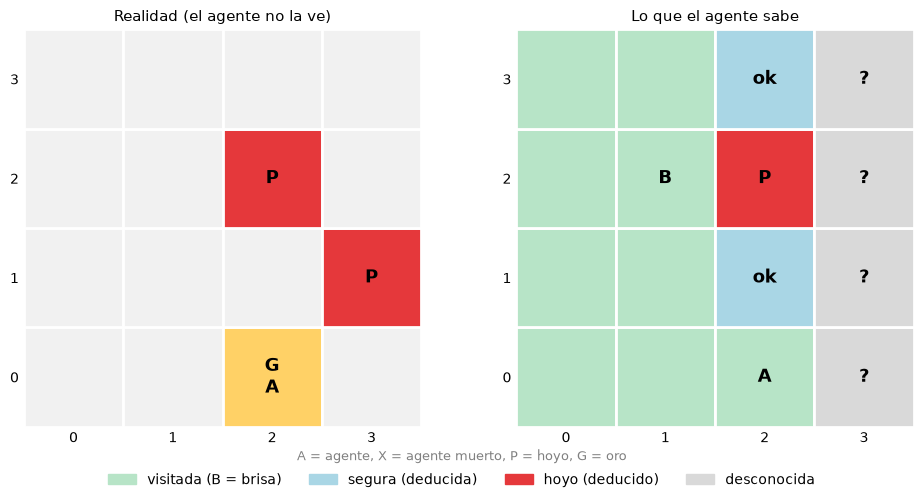

In [12]:
# Un episodio completo (semilla 20), narrando el razonamiento paso a paso
modelo_ok = WumpusModel(rng=20, verbose=True)
while modelo_ok.running:
    modelo_ok.step()

print(f"\n¿Tomó el oro? {modelo_ok.explorer.has_gold} | movimientos arriesgados: {modelo_ok.explorer.risky_moves}")
plot_wumpus(modelo_ok)

**Cómo leer el episodio (semilla 20).** Al llegar a $(1,2)$ en $t=5$ el agente siente brisa. Los otros tres vecinos de esa celda, $(0,2)$, $(1,1)$ y $(1,3)$, ya se sabían libres de hoyos (el agente visitó dos de ellos y había deducido que $(1,1)$ era segura); el único vecino que puede explicar la brisa es $(2,2)$. Formalmente, de $B_{1,2} \Leftrightarrow (P_{0,2}\vee P_{2,2}\vee P_{1,1}\vee P_{1,3})$ y de los hechos $\neg P_{0,2}$, $\neg P_{1,1}$, $\neg P_{1,3}$ se sigue $P_{2,2}$. El agente *no probó suerte*: **dedujo** que había un hoyo y rodeó ese peligro.

[t= 0] en (0, 0): brisa=False | seguras: [(0, 1), (1, 0)] | hoyos deducidos: [] → va a (0, 1)
[t= 1] en (0, 1): brisa=True  | seguras: [(1, 0)] | hoyos deducidos: [] → va a (0, 0)
[t= 2] en (0, 0): brisa=False | seguras: [(1, 0)] | hoyos deducidos: [] → va a (1, 0)
[t= 3] en (1, 0): brisa=True  | seguras: [] | hoyos deducidos: [] → va a (1, 1)  ¡RIESGO!
[t= 3]       ...y cae en un hoyo

¿Tomó el oro? False | ¿sigue vivo? False


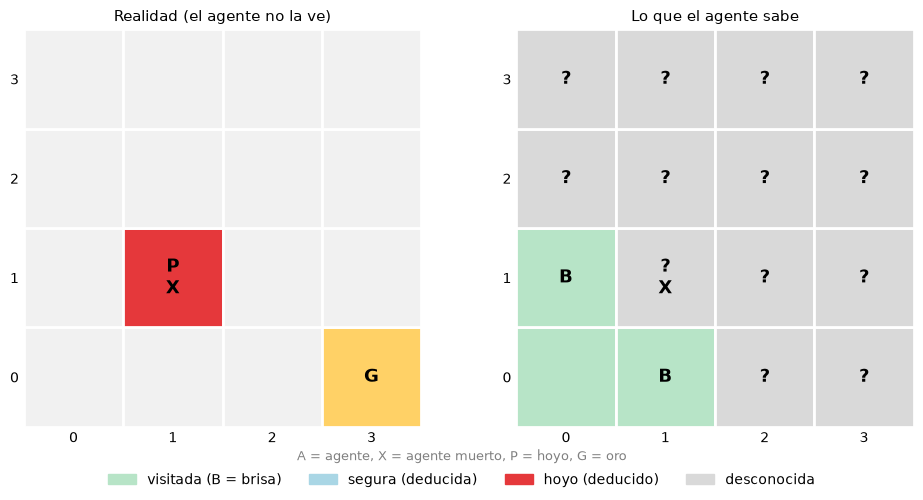

In [13]:
# Un episodio donde el agente se ve obligado a arriesgarse (semilla 6)
modelo_riesgo = WumpusModel(rng=6, verbose=True)
while modelo_riesgo.running:
    modelo_riesgo.step()

print(f"\n¿Tomó el oro? {modelo_riesgo.explorer.has_gold} | ¿sigue vivo? {modelo_riesgo.explorer.alive}")
plot_wumpus(modelo_riesgo)

**El dilema de la semilla 6.** El agente siente brisa en $(0,1)$ y en $(1,0)$. Las celdas candidatas a tener hoyo son $(0,2)$, $(1,1)$ y $(2,0)$, y las restricciones son $P_{0,2}\vee P_{1,1}$ y $P_{1,1}\vee P_{2,0}$. Ninguna celda se puede *garantizar* como segura, así que la KB responde `desconocido` para todas y el agente debe elegir sin garantías.

Pero **no todas las opciones son igual de riesgosas**. Si contamos los modelos de esas tres celdas compatibles con ambas restricciones, hay 5, y en 4 de ellos hay un hoyo en $(1,1)$: una sola celda con hoyo explica ambas brisas, mientras que evitarla exige dos hoyos. El agente eligió la candidata más cercana, que resultó ser la peor apuesta. La lógica nos dice **qué es seguro**, pero no **cuánto riesgo** hay en lo que no lo es; para eso se necesita razonamiento probabilístico (Tarea 5).

In [14]:
# ¿Qué tan grande es la KB del agente y por qué enumerar modelos no es una opción?
agente = modelo_ok.explorer
simbolos = {lit_symbol(l) for c in agente.kb.clauses for l in c}
print(f"Símbolos en la KB: {len(simbolos)}  ->  {2**len(simbolos):,} modelos posibles (inviable enumerarlos)")
print(f"Cláusulas en la KB: {len(agente.kb.clauses)}")
print(f"Consultas ASK resueltas con DPLL en el episodio: {agente.kb.n_ask}")

Símbolos en la KB: 33  ->  8,589,934,592 modelos posibles (inviable enumerarlos)
Cláusulas en la KB: 86
Consultas ASK resueltas con DPLL en el episodio: 147


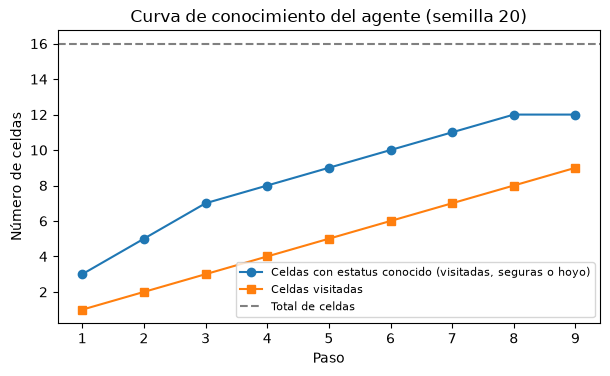

In [15]:
# Curva de conocimiento: el equivalente a la "curva de aprendizaje" del notebook anterior
datos = modelo_ok.datacollector.get_model_vars_dataframe().reset_index(drop=True)
pasos = np.arange(1, len(datos) + 1)

plt.figure(figsize=(7, 3.8))
plt.plot(pasos, datos["Conocidas"], marker="o", label="Celdas con estatus conocido (visitadas, seguras o hoyo)")
plt.plot(pasos, datos["Visitadas"], marker="s", label="Celdas visitadas")
plt.axhline(modelo_ok.width * modelo_ok.height, ls="--", color="gray", label="Total de celdas")
plt.xlabel("Paso")
plt.ylabel("Número de celdas")
plt.title("Curva de conocimiento del agente (semilla 20)")
plt.legend(fontsize=8, loc="lower right")
plt.show()

La curva de celdas conocidas **nunca decrece**: es la **monotonía** de la lógica en acción. A diferencia de los `q_values` del notebook anterior, que se corrigen con cada recompensa, aquí lo deducido es definitivo mientras la KB sea verdadera.

### Evaluación por lotes

Repetimos el experimento con 300 mundos distintos (una semilla por mundo). Además de medir el éxito, comprobamos empíricamente la **solidez**: el agente nunca debe morir en un movimiento que su propia KB declaró seguro.

In [16]:
def run_wumpus(rng, p_pit=0.2, verbose=False, max_steps=200):
    """Corre un episodio completo y devuelve sus métricas."""
    model = WumpusModel(p_pit=p_pit, rng=rng, verbose=verbose)
    while model.running and model.steps < max_steps:
        model.step()
    a = model.explorer
    return {"exito": a.has_gold, "muerto": not a.alive, "riesgos": a.risky_moves,
            "pasos": model.steps, "murio_en_seguro": a.died_on_safe_move}


episodios = pd.DataFrame([run_wumpus(rng=s) for s in range(300)])

resumen = pd.Series({
    "Episodios": len(episodios),
    "Éxito (%)": 100 * episodios.exito.mean(),
    "Muerte (%)": 100 * episodios.muerto.mean(),
    "Se rinde (%)": 100 * (~episodios.exito & ~episodios.muerto).mean(),
    "Éxito sin ningún riesgo (%)": 100 * (episodios.exito & (episodios.riesgos == 0)).mean(),
    "Movimientos arriesgados por episodio": episodios.riesgos.mean(),
    "Muertes tras un movimiento 'seguro'": int(episodios.murio_en_seguro.sum()),
})
print(resumen.round(2).to_string())

Episodios                               300.00
Éxito (%)                                65.67
Muerte (%)                               34.33
Se rinde (%)                              0.00
Éxito sin ningún riesgo (%)              49.67
Movimientos arriesgados por episodio      0.69
Muertes tras un movimiento 'seguro'       0.00


**Qué muestran los números.** Todas las muertes ocurren **después de un movimiento arriesgado** (la última fila vale 0): cuando la KB declara una celda segura, lo es. Eso es la solidez de la inferencia más la verdad de las reglas del mundo. Las muertes restantes son el precio de los momentos en que *ninguna* celda es segura, como en la semilla 6; frecuentemente ocurren en el primer paso, cuando la celda inicial ya tiene brisa y el agente no tiene información alguna.

### Tareas para los estudiantes (Ejercicio 1)

1. **(Básico) Seguir una deducción a mano.** Para el episodio de la semilla 20, escribe las oraciones de la KB relevantes en el paso en que el agente llega a $(1,2)$ y demuestra con `tt_entails` que $KB \models P_{2,2}$. Pista: usa sólo los símbolos involucrados; con 5 símbolos la tabla de verdad tiene 32 filas.
2. **(Básico) El bicondicional importa.** En `WumpusAgent.__init__` reemplaza `Iff(B(x, y), Or(...))` por `Implies(B(x, y), Or(...))` (sólo "brisa ⇒ hoyo cerca"). Ejecuta la evaluación por lotes. ¿Qué deducciones se pierden? ¿Cómo cambian el éxito, las muertes y el número de movimientos arriesgados? Explícalo con las direcciones $\Rightarrow$ y $\Leftarrow$.
3. **(Básico) Densidad de hoyos.** Barre `p_pit` en $\{0.1, 0.2, 0.3, 0.4\}$ con `run_wumpus` y grafica éxito, muerte y movimientos arriesgados. ¿Por qué ayuda menos la lógica cuando hay más hoyos?
4. **(Intermedio) Curva de conocimiento.** Promedia la curva de `Conocidas` sobre muchos episodios y compárala con la curva de aprendizaje del notebook anterior. ¿Qué agente "sabe" algo útil desde el primer paso? ¿Qué pasaría con la monotonía si los hoyos se movieran?
5. **(Intermedio) Mejor política de riesgo.** Cuando no hay celdas seguras, en lugar de elegir la candidata más cercana, **cuenta modelos**: para cada candidata, cuenta (con `models_of` sobre las restricciones de la frontera) en qué fracción de los modelos tiene hoyo, y elige la de menor fracción. Compara la tasa de éxito y revisa qué ocurre en la semilla 6.
6. **(Avanzado) Añadir al Wumpus.** Introduce los símbolos $W_{x,y}$ (hay Wumpus) y $S_{x,y}$ (hay hedor), la regla $S_{x,y} \Leftrightarrow \bigvee_{N(x,y)} W_{a,b}$ y la oración "hay exactamente un Wumpus" (usa `exactly(1, ...)`, que se define en el Ejercicio 2). Extiende las percepciones y el agente.
7. **(Avanzado) Conocimiento frente a aprendizaje.** Adapta el `LearningAgent` del notebook anterior a este mundo (recompensa $-1000$ al caer en un hoyo, $+1000$ por el oro). ¿Cuántos episodios necesita para igualar el desempeño de este agente, que no necesita ninguno? ¿Qué le aporta cada enfoque?

## 7. Ejercicio 2: Buscaminas simplificado

El **Buscaminas** tiene la misma estructura lógica que las brisas del Wumpus, con una diferencia fundamental: la percepción es un **número exacto**. Una celda destapada muestra cuántas de sus ocho vecinas tienen mina.

| | Wumpus (hoyos) | Buscaminas |
|---|---|---|
| **Percepción** | brisa: *al menos un* vecino tiene hoyo | número $k$: *exactamente $k$* vecinos tienen mina |
| **Vecindad** | 4 vecinos (ortogonal) | 8 vecinos (Moore) |
| **Restricción** | disyunción $\vee$ | **cardinalidad** ("exactamente $k$ de $n$") |
| **Un error…** | el agente cae en un hoyo | el jugador pierde |

**Descripción del modelo**

*Entorno*: tablero $6\times6$ (`SingleGrid`) con 6 minas. `Mine` es un agente de Mesa, igual que `Pit` en el ejercicio anterior.

*Simplificaciones*: (1) la **primera jugada es gratuita**: se destapa una celda cuya vecindad no tiene minas, de modo que muestra $0$ (en la mayoría de implementaciones la primera jugada nunca explota); (2) **no hay apertura en cascada** ni banderas: el agente sólo decide qué celda destapar; (3) el agente **no usa** el número total de minas.

*Percepción*: el tablero visible, es decir, el número de cada celda destapada.

*Conocimiento*: por cada celda destapada $c$ con número $k$ y vecinas $N(c)$ se hace `TELL` de

$$
\neg M_c \;\wedge\; \Big(\textstyle\sum_{v \in N(c)} [M_v] = k\Big)
$$

La lógica proposicional no sabe "contar", así que la restricción se **codifica en cláusulas**. Si $|N| = n$:

* **a lo sumo $k$ minas**: todo subconjunto de $k+1$ vecinas contiene alguna sin mina: $\;\bigwedge_{|S|=k+1}\ \bigvee_{v\in S}\neg M_v$
* **al menos $k$ minas**: todo subconjunto de $n-k+1$ vecinas contiene alguna con mina: $\;\bigwedge_{|S|=n-k+1}\ \bigvee_{v\in S} M_v$

En total son $\binom{n}{k+1}+\binom{n}{k-1}$ cláusulas (con $\binom{n}{-1}=0$).

*Decisión* (en cada paso):

1. Para cada celda oculta de la **frontera** (con al menos una vecina destapada) hacer `ASK` de $\neg M$ ("segura") y de $M$ ("mina"). Lo deducido se anota con `TELL`.
2. Destapar una celda segura.
3. Si no hay ninguna: **adivinar** una celda oculta que no sea una mina deducida. Cada adivinanza se registra.

In [17]:
def exactly(k, simbolos):
    """Oración (en CNF) que dice: exactamente k de los símbolos son verdaderos."""
    n = len(simbolos)
    assert 0 <= k <= n
    clausulas = []
    # a lo sumo k: toda combinación de k+1 símbolos tiene alguno falso
    for combo in combinations(simbolos, k + 1):
        clausulas.append(Or(*[Not(s) for s in combo]))
    # al menos k: toda combinación de n-k+1 símbolos tiene alguno verdadero
    for combo in combinations(simbolos, n - k + 1):
        clausulas.append(Or(*combo))
    return And(*clausulas)


# --- Ejemplo: una celda muestra "1" y tiene tres vecinas ocultas a, b, c ---
a, b, c = "M_a", "M_b", "M_c"
regla = exactly(1, [a, b, c])
print("Cláusulas para 'exactamente 1 de 3':", len(to_clauses(regla)), "= C(3,2) + C(3,0) =", comb(3, 2) + comb(3, 0))

kb = KnowledgeBase()
kb.tell(regla)
print(f"\n¿Hay mina en a?  {kb.ask_status(a)}")       # con un solo dato no se puede saber
kb.tell(Not(a))
kb.tell(Not(b))
print(f"Si a y b están libres, ¿hay mina en c?  {kb.ask_status(c)}")

# --- Un caso sin solución lógica: 'exactamente 1 de 2' (el clásico 50/50) ---
kb = KnowledgeBase()
kb.tell(exactly(1, [a, b]))
print(f"\n50/50:  mina en a -> {kb.ask_status(a)}  |  mina en b -> {kb.ask_status(b)}")

# --- Crecimiento del número de cláusulas ---
print("\nCláusulas para 'exactamente k de 8 vecinas':")
print({k: len(to_clauses(exactly(k, [f'M_{i}' for i in range(8)]))) for k in range(9)})
print(f"Restricción global '6 minas entre 36 celdas': {comb(36, 7) + comb(36, 5):,} cláusulas")

Cláusulas para 'exactamente 1 de 3': 4 = C(3,2) + C(3,0) = 4

¿Hay mina en a?  desconocido
Si a y b están libres, ¿hay mina en c?  verdadero

50/50:  mina en a -> desconocido  |  mina en b -> desconocido

Cláusulas para 'exactamente k de 8 vecinas':
{0: 8, 1: 29, 2: 64, 3: 98, 4: 112, 5: 98, 6: 64, 7: 29, 8: 8}
Restricción global '6 minas entre 36 celdas': 8,724,672 cláusulas


**Observaciones.** Cada número del tablero genera hasta 112 cláusulas (el máximo, con 8 vecinas y $k=4$), manejable. Pero el mismo método aplicado a la restricción *global* "hay exactamente 6 minas en las 36 celdas" necesitaría casi **9 millones de cláusulas**. Por eso el agente no la usa: es una limitación real de codificar cardinalidades en lógica proposicional (Tarea 5).

El caso 50/50 es el análogo del dilema del Wumpus: ni "hay mina" ni "no hay mina" se siguen de la KB.

In [18]:
class Mine(Agent):
    """Una mina: peligro fijo en el entorno."""
    def __init__(self, model):
        super().__init__(model)


class MinesweeperAgent(KBAgent):
    """Jugador que razona con lógica sobre dónde hay minas."""
    def __init__(self, model, use_logic=True):
        super().__init__(model)
        self.use_logic = use_logic    # False: jugador aleatorio (línea base de comparación)
        self.told = set()             # celdas destapadas que ya se incorporaron a la KB
        self.safe = set()             # celdas con KB ⊨ ¬M
        self.mines = set()            # celdas con KB ⊨ M
        self.guesses = 0
        self.guess_steps = []         # pasos (1, 2, ...) en que tuvo que adivinar
        self.trace = ""

    # ----- percepción -> oración -----
    def perceive(self):
        return self.model.visible_board()

    def make_percept_sentence(self, board):
        partes = []
        for pos, n in sorted(board.items()):
            if pos in self.told:                      # sólo lo nuevo
                continue
            self.told.add(pos)
            vecinos = self.model.grid.get_neighborhood(pos, moore=True, include_center=False)
            partes.append(Not(M(*pos)))                                # no es mina (si no, habría explotado)
            partes.append(exactly(n, [M(*v) for v in vecinos]))       # exactamente n vecinas con mina
        return And(*partes) if partes else None

    # ----- ASK: ¿qué sé sobre la frontera? -----
    def frontier(self):
        reveladas = self.model.revealed
        celdas = {v for r in reveladas
                  for v in self.model.grid.get_neighborhood(r, moore=True, include_center=False)}
        return sorted(celdas - reveladas)

    def update_knowledge(self):
        for cell in self.frontier():
            if cell in self.safe or cell in self.mines:
                continue
            if self.kb.ask(Not(M(*cell))):              # ¿KB ⊨ ¬M?  -> segura
                self.safe.add(cell)
                self.kb.tell(Not(M(*cell)))
            elif self.kb.ask(M(*cell)):                 # ¿KB ⊨ M?   -> mina
                self.mines.add(cell)
                self.kb.tell(M(*cell))

    def guess(self):
        """Sin certezas: elige al azar una celda oculta que no sea una mina deducida."""
        ocultas = [(x, y) for x in range(self.model.width) for y in range(self.model.height)
                   if (x, y) not in self.model.revealed and (x, y) not in self.mines]
        self.guesses += 1
        self.guess_steps.append(self.t + 1)
        return ("reveal", self.model.random.choice(ocultas), True)

    def choose_action(self):
        self.trace = ""
        if not self.use_logic:
            return self.guess()
        self.update_knowledge()
        por_revelar = sorted(self.safe - self.model.revealed)
        self.trace = f"seguras por revelar: {len(por_revelar):2d} | minas deducidas: {len(self.mines)}"
        if por_revelar:
            return ("reveal", por_revelar[0], False)
        return self.guess()

    def act(self, action):
        _, cell, arriesgado = action
        self.log((self.trace + " " if self.trace else "") + f"→ revela {cell}"
                 + ("  ¡ADIVINANDO!" if arriesgado else ""))
        self.model.reveal(cell)

In [19]:
class MinesweeperModel(Model):
    """Tablero de Buscaminas con un jugador basado en conocimiento."""
    def __init__(self, width=6, height=6, n_mines=6, use_logic=True, rng=None, verbose=False):
        super().__init__(rng=rng)      # rng fija la semilla (en Mesa 3.5 reemplaza al argumento seed)
        self.width, self.height, self.n_mines, self.verbose = width, height, n_mines, verbose
        self.grid = SingleGrid(width, height, torus=False)
        self.revealed = set()
        self.exploded = False
        self.exploded_at = None
        self.won = False

        # Primera jugada gratuita: celda sin minas en su vecindad (mostrará 0)
        self.start = (self.random.randrange(width), self.random.randrange(height))
        prohibidas = {self.start} | set(self.grid.get_neighborhood(self.start, moore=True, include_center=False))
        libres = [(x, y) for x in range(width) for y in range(height) if (x, y) not in prohibidas]
        assert n_mines <= len(libres), "Demasiadas minas para este tablero."
        for pos in self.random.sample(libres, n_mines):
            self.grid.place_agent(Mine(self), pos)

        self.reveal(self.start)
        self.player = MinesweeperAgent(self, use_logic)

        self.datacollector = DataCollector(model_reporters={
            "Reveladas": lambda m: len(m.revealed),
            "Minas deducidas": lambda m: len(m.player.mines),
        })

    # ----- lo que el entorno sabe y lo que deja ver -----
    def has_mine(self, pos):
        return any(isinstance(a, Mine) for a in self.grid.get_cell_list_contents([pos]))

    def number_at(self, pos):
        return sum(self.has_mine(v) for v in self.grid.get_neighborhood(pos, moore=True, include_center=False))

    def visible_board(self):
        """Percepción del jugador: sólo los números de las celdas ya destapadas."""
        return {pos: self.number_at(pos) for pos in self.revealed}

    def reveal(self, pos):
        if self.has_mine(pos):
            self.exploded, self.exploded_at = True, pos
            self.running = False
            return
        self.revealed.add(pos)
        if len(self.revealed) == self.width * self.height - self.n_mines:
            self.won = True
            self.running = False

    def step(self):
        self.player.step()
        self.datacollector.collect(self)

In [20]:
NUM_COLORES = {0: "#9ca3af", 1: "#1d4ed8", 2: "#15803d", 3: "#dc2626", 4: "#1e3a8a",
               5: "#7f1d1d", 6: "#0e7490", 7: "#111827", 8: "#6b7280"}


def plot_minesweeper(model):
    w, h, p = model.width, model.height, model.player
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.9))
    _preparar_ejes(ax1, w, h, "Tablero del jugador y lo que deduce")
    _preparar_ejes(ax2, w, h, "Realidad (el jugador no la ve)")
    for x in range(w):
        for y in range(h):
            c = (x, y)
            # --- panel del jugador ---
            if c in model.revealed:
                n = model.number_at(c)
                _celda(ax1, x, y, "#f1f1f1", str(n), NUM_COLORES[n])
            elif c == model.exploded_at:
                _celda(ax1, x, y, "#7f1d1d", "*", "white", 16)
            elif c in p.mines:
                _celda(ax1, x, y, "#ffadad", "M", "#7f1d1d")
            elif c in p.safe:
                _celda(ax1, x, y, "#a9d6e5", "ok")
            else:
                _celda(ax1, x, y, "#bdbdbd")
            # --- panel de la realidad ---
            if model.has_mine(c):
                _celda(ax2, x, y, "#e5383b", "*", "white", 16)
            else:
                n = model.number_at(c)
                _celda(ax2, x, y, "#f1f1f1", str(n), NUM_COLORES[n])
    leyenda = [Rectangle((0, 0), 1, 1, facecolor=c) for c in ("#f1f1f1", "#a9d6e5", "#ffadad", "#bdbdbd", "#7f1d1d")]
    fig.legend(leyenda, ["destapada", "segura (deducida)", "mina (deducida)", "oculta sin información", "mina que explotó"],
               loc="lower center", ncol=5, frameon=False, fontsize=9)
    plt.tight_layout(rect=[0, 0.07, 1, 1])
    plt.show()

### Ejecución de una partida

La primera línea del registro corresponde a la primera acción del agente (la jugada gratuita ya fue destapada por el entorno). Observa cómo crece el número de **minas deducidas** y cuándo el agente se queda sin celdas seguras.

[t= 0] seguras por revelar:  5 | minas deducidas: 0 → revela (0, 0)
[t= 1] seguras por revelar:  4 | minas deducidas: 0 → revela (0, 1)
[t= 2] seguras por revelar:  5 | minas deducidas: 0 → revela (0, 2)
[t= 3] seguras por revelar:  6 | minas deducidas: 0 → revela (0, 3)
[t= 4] seguras por revelar:  5 | minas deducidas: 0 → revela (1, 1)
[t= 5] seguras por revelar:  5 | minas deducidas: 0 → revela (1, 2)
[t= 6] seguras por revelar:  5 | minas deducidas: 0 → revela (1, 3)
[t= 7] seguras por revelar:  4 | minas deducidas: 1 → revela (2, 0)
[t= 8] seguras por revelar:  5 | minas deducidas: 1 → revela (2, 1)
[t= 9] seguras por revelar:  4 | minas deducidas: 2 → revela (2, 2)
[t=10] seguras por revelar:  3 | minas deducidas: 3 → revela (2, 3)
[t=11] seguras por revelar:  2 | minas deducidas: 3 → revela (3, 0)
[t=12] seguras por revelar:  3 | minas deducidas: 3 → revela (3, 1)
[t=13] seguras por revelar:  3 | minas deducidas: 3 → revela (4, 0)
[t=14] seguras por revelar:  4 | minas deducidas

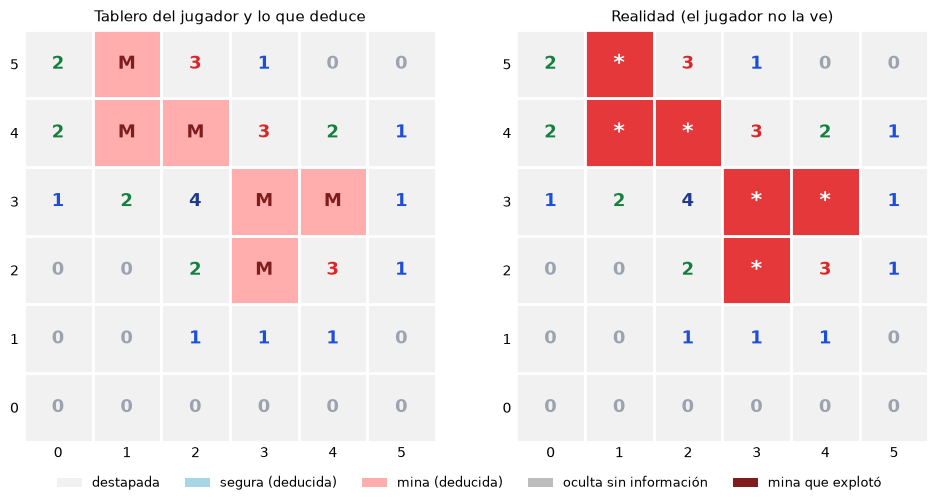

In [21]:
# Una partida completa (semilla 18), narrando el razonamiento paso a paso
juego = MinesweeperModel(rng=18, verbose=True)
while juego.running:
    juego.step()

print(f"\n¿Ganó? {juego.won} | pasos: {juego.steps} | adivinanzas: {juego.player.guesses} | consultas ASK: {juego.player.kb.n_ask}")
plot_minesweeper(juego)

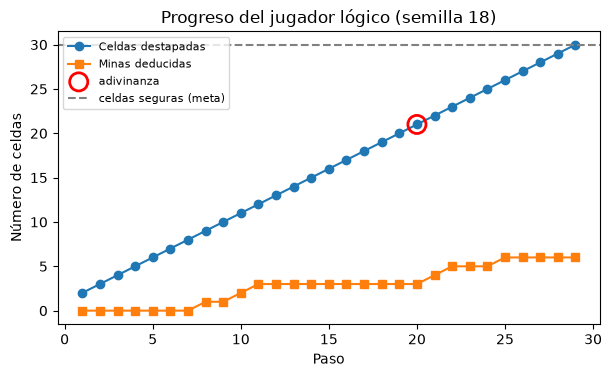

In [22]:
def curva_buscaminas(model, titulo):
    datos = model.datacollector.get_model_vars_dataframe().reset_index(drop=True)
    pasos = np.arange(1, len(datos) + 1)
    plt.figure(figsize=(7, 3.8))
    plt.plot(pasos, datos["Reveladas"], marker="o", label="Celdas destapadas")
    plt.plot(pasos, datos["Minas deducidas"], marker="s", label="Minas deducidas")
    for i, k in enumerate(model.player.guess_steps):
        plt.scatter([k], [datos["Reveladas"][k - 1]], s=170, facecolors="none", edgecolors="red",
                    linewidths=2, zorder=5, label="adivinanza" if i == 0 else None)
    plt.axhline(model.width * model.height - model.n_mines, ls="--", color="gray", label="celdas seguras (meta)")
    plt.xlabel("Paso")
    plt.ylabel("Número de celdas")
    plt.title(titulo)
    plt.legend(fontsize=8, loc="upper left")
    plt.show()

curva_buscaminas(juego, "Progreso del jugador lógico (semilla 18)")

**Lectura de la curva.** El avance es casi lineal: cada paso destapa una celda que el agente **sabía** que era segura. Los círculos rojos marcan los momentos en que la KB no tenía ninguna celda segura y el agente tuvo que adivinar (en la semilla 18, una vez). Después de un golpe de suerte, nueva información abre nuevas deducciones y el agente vuelve a avanzar sin riesgo.

A continuación, una partida que el agente **pierde** (semilla 32).

¿Ganó? False | adivinanzas: 2 | explotó en: (1, 4)


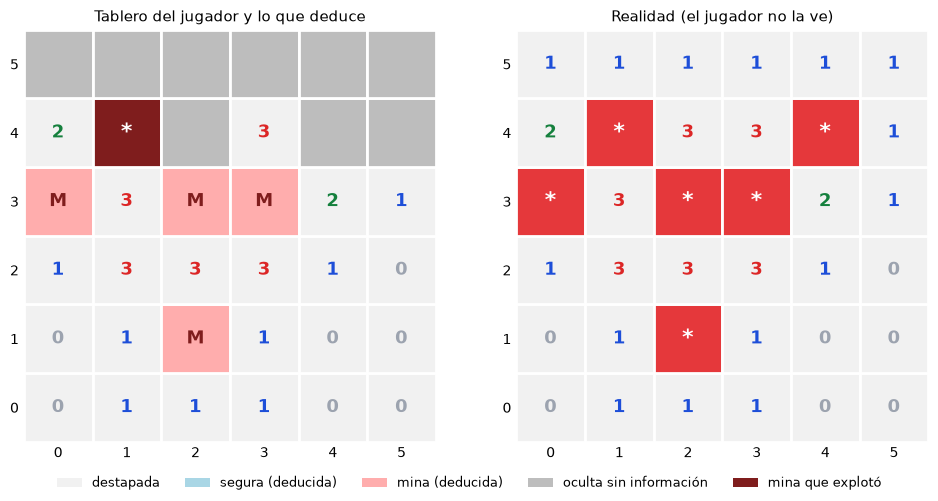

In [23]:
juego_perdido = MinesweeperModel(rng=32)
while juego_perdido.running:
    juego_perdido.step()

print(f"¿Ganó? {juego_perdido.won} | adivinanzas: {juego_perdido.player.guesses} | "
      f"explotó en: {juego_perdido.exploded_at}")
plot_minesweeper(juego_perdido)

### Lógica frente a azar

Comparamos al agente basado en conocimiento con un **jugador aleatorio** (`use_logic=False`, que destapa celdas al azar). Ambos juegan los *mismos* tableros (misma semilla), de modo que la comparación es pareada.

In [24]:
def jugar(use_logic=True, rng=None, verbose=False, **kwargs):
    """Juega una partida completa y devuelve sus métricas."""
    model = MinesweeperModel(use_logic=use_logic, rng=rng, verbose=verbose, **kwargs)
    while model.running:
        model.step()
    p = model.player
    return {"gana": model.won, "pasos": model.steps, "adivinanzas": p.guesses,
            "reveladas": len(model.revealed), "consultas": p.kb.n_ask}


def comparar(n_partidas=200, **kwargs):
    """Compara el agente lógico con el jugador aleatorio en los mismos tableros."""
    columnas = {}
    for nombre, logica in (("Agente lógico", True), ("Jugador aleatorio", False)):
        df = pd.DataFrame([jugar(use_logic=logica, rng=s, **kwargs) for s in range(n_partidas)])
        columnas[nombre] = {
            "Victorias (%)": 100 * df.gana.mean(),
            "Celdas destapadas (prom.)": df.reveladas.mean(),
            "Adivinanzas por partida": df.adivinanzas.mean(),
            "Victorias sin adivinar (%)": 100 * (df.gana & (df.adivinanzas == 0)).mean(),
            "Derrotas sin haber adivinado": int((~df.gana & (df.adivinanzas == 0)).sum()),
            "Consultas ASK por partida": df.consultas.mean(),
        }
    return pd.DataFrame(columnas).round(2)


comparar(n_partidas=200)

,Agente lógico,Jugador aleatorio
Victorias (%),86.00,0.00
Celdas destapadas (prom.),29.16,5.24
Adivinanzas por partida,0.54,5.24
Victorias sin adivinar (%),63.00,0.00
Derrotas sin haber adivinado,0.00,0.00
Consultas ASK por partida,181.50,0.00


**Qué muestran los números.**

* El jugador aleatorio prácticamente nunca gana: tiene que destapar las 30 celdas seguras sin tropezar con ninguna de las 6 minas.
* El agente lógico gana la gran mayoría de las partidas, y la mayoría de sus victorias ocurren **sin adivinar ni una vez**: sólo con deducción.
* La fila *"Derrotas sin haber adivinado"* vale 0: **toda derrota del agente lógico sigue a una adivinanza**, nunca a una deducción. De nuevo, la solidez.

### Tareas para los estudiantes (Ejercicio 2)

1. **(Básico) Contar cláusulas.** Verifica con `len(to_clauses(exactly(k, ...)))` la fórmula $\binom{n}{k+1}+\binom{n}{k-1}$ para $n=8$ y $k=0,\dots,8$. ¿Para qué $k$ es máxima? ¿Por qué la tabla es simétrica?
2. **(Básico) Lógica frente a azar.** Usa `comparar(200, n_mines=...)` con $3, 6, 9, 12$ minas y grafica victorias y adivinanzas del agente lógico. ¿A partir de qué densidad de minas la deducción ya no basta?
3. **(Básico) Casos indecidibles.** Construye con `KnowledgeBase` otra configuración, distinta del 50/50, en la que la KB no pueda decidir (por ejemplo, `exactly(1, [a, b, c])` sin más información) y comprueba las tres respuestas de `ask_status`. Luego revisa en la partida de la semilla 32 el momento en que el agente adivinó y explica por qué su KB no podía decidir.
4. **(Intermedio) Expansión en cascada.** Implementa en `MinesweeperModel.reveal` la apertura automática de las vecinas cuando el número es 0. Compara número de pasos y de consultas ASK. ¿La KB ya habría podido deducir esas celdas sola?
5. **(Intermedio) Restricción global de minas.** Añade el conocimiento "hay exactamente `n_mines` minas" **sólo cuando queden pocas celdas ocultas** (por ejemplo, $\le 10$), y mide cuántas partidas adicionales se ganan. Explica por qué no se puede codificar desde el inicio (observa el recuento de la celda de ejemplo).
6. **(Avanzado) Mejor adivinanza.** En `guess()`, en vez de elegir al azar, calcula por conteo de modelos la probabilidad de mina de cada celda de la frontera (y compárala con la de las celdas fuera de la frontera) y elige la de menor probabilidad. Mide cuánto sube la tasa de victorias.
7. **(Avanzado) Escalabilidad.** Mide el tiempo por partida en tableros de $6\times6$, $8\times8$ y $10\times10$ manteniendo la densidad de minas (~17%). ¿Qué crece más rápido: el número de cláusulas, el número de consultas o el tiempo por consulta? Propón una optimización (por ejemplo, consultar sólo las celdas de la frontera cuyas vecinas cambiaron).

## 8. Síntesis y discusión

**Lo que aprendimos**

* Un agente basado en conocimiento **separa** lo que sabe (la KB) de cómo razona (el algoritmo de inferencia). Cambiar las reglas del mundo no exige reescribir la lógica de decisión.
* La **consecuencia lógica** ($KB \models \alpha$) da garantías: si las reglas son correctas y la inferencia es sólida, todo lo que el agente declara seguro lo es. Lo verificamos empíricamente en ambos ejercicios.
* Una KB casi nunca lo sabe todo: existe la respuesta **desconocido**. Cuando es la única que queda, el agente debe arriesgarse, y la lógica por sí sola **no dice cómo hacerlo bien**.
* El costo de la inferencia importa: la enumeración de modelos es exponencial; DPLL con propagación de unidades hace viables KB con decenas de símbolos, aunque la propia representación (un símbolo por celda, cardinalidades como cláusulas) crece rápidamente.

**Preguntas para la discusión**

1. En el Wumpus y en el Buscaminas la KB dice "desconocido" y el agente adivina. ¿Cómo se debería elegir la mejor apuesta? ¿Qué herramienta matemática falta? *(Pista: razonamiento probabilístico; en el Buscaminas decidir si una configuración parcial es consistente es un problema NP‑completo, Kaye, 2000.)*
2. Las reglas del mundo las escribimos a mano. ¿Qué pasaría si estuvieran mal? ¿Podría un agente **aprender** las reglas de la KB a partir de la experiencia?
3. Tuvimos que escribir un símbolo por cada celda. ¿Qué expresividad nos daría la **lógica de primer orden** (variables y cuantificadores: "para toda celda $c$, brisa en $c$ si y sólo si hay un hoyo en algún vecino de $c$")?
4. **Conocimiento + aprendizaje.** El `LearningAgent` del notebook anterior explora al azar con probabilidad $\epsilon$, lo que en el Wumpus lo llevaría a caer en hoyos. ¿Cómo combinar ambos enfoques? *(Idea: la KB filtra las acciones **demostrablemente seguras** y los `q_values` eligen entre ellas: exploración segura.)*

### Referencias

* Russell, S. y Norvig, P. *Artificial Intelligence: A Modern Approach*, capítulo 7 (*Logical Agents*).
* Newell, A. (1982). The knowledge level. *Artificial Intelligence*, 18(1), 87–127.
* Davis, M., Logemann, G. y Loveland, D. (1962). A machine program for theorem-proving. *Communications of the ACM*, 5(7), 394–397.
* Kaye, R. (2000). Minesweeper is NP-complete. *The Mathematical Intelligencer*, 22(2), 9–15.